In [29]:
from cfb.config import ROOT, SQL_ANALYSIS_DIR
from cfb.db import engine, read_query
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# modeling (scikit-learn)
import joblib                                                   # save / load the trained model
from sklearn.linear_model import LogisticRegression             # baseline model
from sklearn.ensemble import HistGradientBoostingClassifier     # main model: handles NULLs, monotonic constraints
from sklearn.pipeline import (make_pipeline, Pipeline)
from sklearn.impute import SimpleImputer                        # fill NULLs for the baseline (logistic can't take them)
from sklearn.preprocessing import (StandardScaler,SplineTransformer,OneHotEncoder)
from sklearn.isotonic import IsotonicRegression                 # calibrate probabilities on the validation season
from sklearn.calibration import calibration_curve, CalibrationDisplay
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
from sklearn.model_selection import train_test_split,GridSearchCV,PredefinedSplit
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
)

import tensorflow as tf
from tensorflow.keras import Sequential, regularizers
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Activation
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

In [30]:
def plot_history(history, title="Learning curves"):
    h = history.history
    epochs = np.arange(1, len(h["loss"]) + 1)
    best_epoch = int(np.argmin(h["val_loss"])) + 1
    fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
    axes[0].plot(epochs, h["loss"], label="Training loss")
    axes[0].plot(epochs, h["val_loss"], label="Validation loss")
    axes[0].axvline(best_epoch, linestyle=":", color="gray",
                    label=f"Min val loss: {best_epoch}")
    axes[0].set_ylabel("BCE + any L2 penalty")
    axes[0].legend()
    axes[0].grid(True)
    axes[1].plot(epochs, h["auc"], label="Training ROC AUC")
    axes[1].plot(epochs, h["val_auc"], label="Validation ROC AUC")
    axes[1].axvline(best_epoch, linestyle=":", color="gray")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("ROC AUC")
    axes[1].legend()
    axes[1].grid(True)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [31]:
go_query = '''
WITH df AS (
    SELECT f.*, g.game_date,
           CASE WHEN f.outcome = 'converted' THEN 1 ELSE 0 END AS convert_target
    FROM marts.fourth_down_features f
    JOIN core.games g ON g.game_id = f.game_id
    WHERE f.decision = 'go'
        AND distance > 0
)
SELECT
    d.*,
    -- earlier attempts by this offense in this game
    count(*)            OVER game_prior AS fourth_down_atts_game,
    sum(convert_target) OVER game_prior AS fourth_down_conv_game,
    -- earlier attempts by this offense this season (previous games + earlier in this game)
    count(*)            OVER szn_prior  AS fourth_down_atts_season,
    sum(convert_target) OVER szn_prior  AS fourth_down_conv_season
FROM df d
WINDOW
    game_prior AS (PARTITION BY offense, game_id ORDER BY play_id
                   ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING),
    szn_prior  AS (PARTITION BY offense, season ORDER BY game_date, game_id, play_id
                   ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
'''
df = pd.read_sql(go_query, engine)
go = df.copy()

In [32]:
go.head()

,play_id,game_id,drive_id,season,week,offense,defense,decision,distance,yards_to_goal,...,fg_pct_szn,fg_att_szn,off_games_prior,outcome,game_date,convert_target,fourth_down_atts_game,fourth_down_conv_game,fourth_down_atts_season,fourth_down_conv_season
0,332990166188,332990166,33299016624,2013,9,Abilene Christian,New Mexico State,go,1,54,...,NaN,NaN,0,failed,2013-10-26,0,0,NaN,0,NaN
1,332990166206,332990166,33299016626,2013,9,Abilene Christian,New Mexico State,go,1,39,...,NaN,NaN,0,converted,2013-10-26,1,1,0.0,1,0.0
2,332990166218,332990166,33299016626,2013,9,Abilene Christian,New Mexico State,go,5,5,...,NaN,NaN,0,converted,2013-10-26,1,2,1.0,2,1.0
3,400799923102954004,400799923,40079992311,2015,1,Abilene Christian,Fresno State,go,2,27,...,NaN,NaN,0,converted,2015-09-03,1,0,NaN,0,NaN
4,400799923103857909,400799923,40079992315,2015,1,Abilene Christian,Fresno State,go,13,27,...,NaN,NaN,0,failed,2015-09-03,0,1,1.0,1,1.0


Text(0.5, 1.0, 'Target Distribution (TO counts as Fail)')

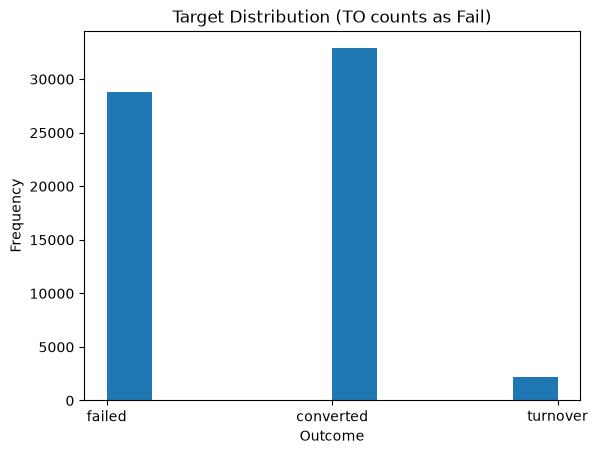

In [33]:
plt.hist(x=go['outcome'])
plt.xlabel('Outcome')
plt.ylabel('Frequency')
plt.title('Target Distribution (TO counts as Fail)')

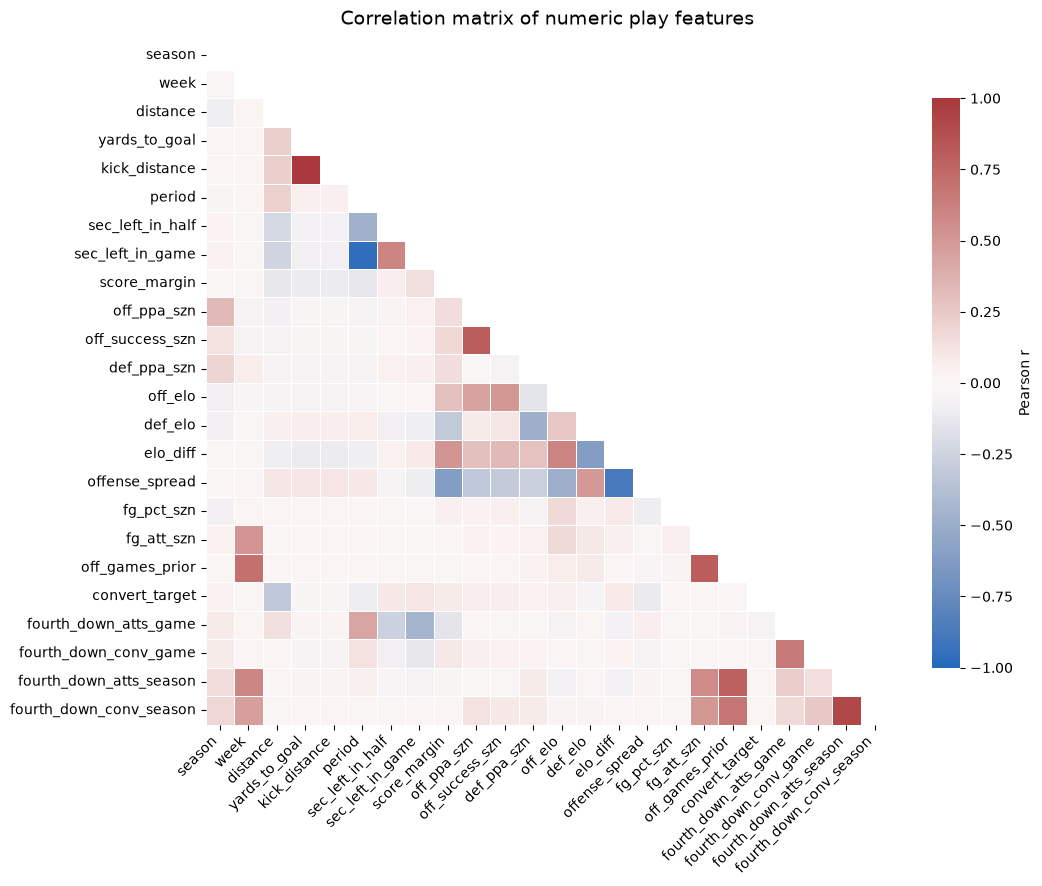

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Numeric columns, minus IDs and anything with no variance
num = (
    go.select_dtypes(include='number')
      .drop(columns=['play_id', 'game_id', 'drive_id', 'old_game_id'], errors='ignore')
)
num = num.loc[:, num.nunique(dropna=True) > 1]   # drop constant / all-NaN columns

corr = num.corr(method='pearson', min_periods=30)

# Mask the redundant upper triangle (and the diagonal)
mask = np.triu(np.ones_like(corr, dtype=bool))

n = len(corr)
fig, ax = plt.subplots(figsize=(max(8, n * 0.45), max(6, n * 0.4)))

sns.heatmap(
    corr,
    mask=mask,
    cmap='vlag',            # diverging: blue = negative, red = positive
    center=0, vmin=-1, vmax=1,
    square=True,
    linewidths=0.5, linecolor='white',
    annot=n <= 20,          # only annotate when it stays readable
    fmt='.2f', annot_kws={'size': 8},
    cbar_kws={'shrink': 0.7, 'label': 'Pearson r'},
    ax=ax,
)

ax.set_title('Correlation matrix of numeric play features', fontsize=14, pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [35]:
# Drop Identifiers and Descriptors
go = go.drop(columns=['play_id', 'game_id','drive_id','offense','defense','decision','outcome','game_date'], errors='ignore')

X = go.drop(columns='convert_target', errors='ignore')
y = go['convert_target']

preprocessor = make_pipeline(
    SimpleImputer(strategy='median', add_indicator=True),
    StandardScaler()
)

# Make splits before to maintain test integrity
X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_development,
    y_development,
    test_size=1/9,
    random_state=42
)

# Scale the training data
X_train_scaled = preprocessor.fit_transform(X_train).astype('float32')
X_val_scaled = preprocessor.transform(X_val).astype('float32')
X_test_scaled = preprocessor.transform(X_test).astype('float32')

# Check the sets
print("Training:", X_train_scaled.shape, np.bincount(y_train))
print("Validation:", X_val_scaled.shape, np.bincount(y_val))
print("Test:", X_test_scaled.shape, np.bincount(y_test))
print("Convert proportion:", f"{y.mean():.1%}")
print("Input features:", X_train_scaled.shape[1])

Training: (51063, 40) [24768 26295]
Validation: (6383, 40) [3095 3288]
Test: (6383, 40) [3105 3278]
Convert proportion: 51.5%
Input features: 40


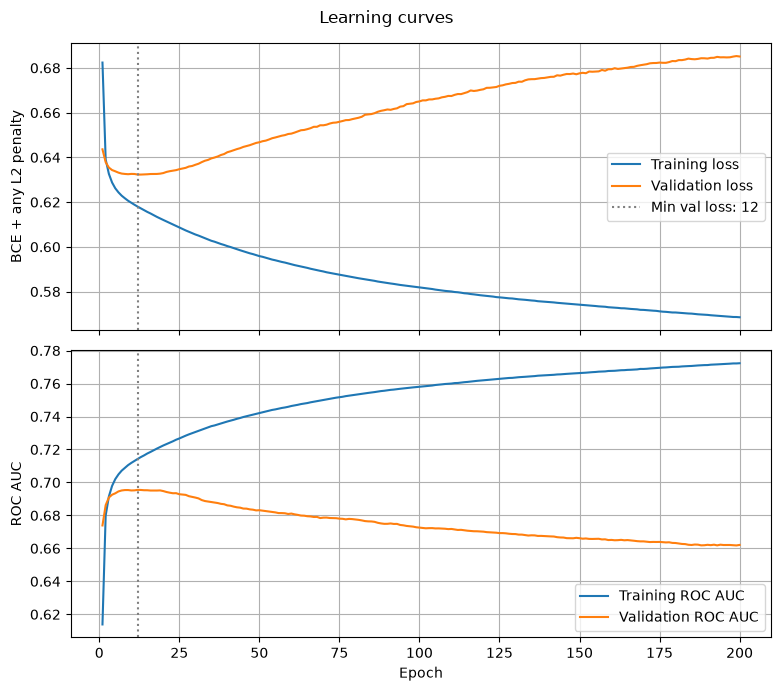

1596/1596 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Training AUC Score      : 0.7739004030803844
Validation AUC Score    : 0.6620472840976537
Validation Accuracy     : 0.621024596584678
Validation F1           : 0.6481454545454546


In [36]:
num_features = X_train_scaled.shape[1]

base_model = Sequential([
    Input(shape=(num_features,)), # Features in a 1D array
    Dense(64, activation='relu', kernel_initializer="he_normal"),
    Dense(32, activation='relu', kernel_initializer="he_normal"),
    Dense(1, activation="sigmoid") # 1 output because its either converted or not
])

opt = Adam(learning_rate=0.001)

base_model.compile(loss='binary_crossentropy',
                    optimizer=opt,
                    metrics=[tf.keras.metrics.F1Score(average='macro',threshold=0.5),tf.keras.metrics.AUC(name='auc')])

base_history = base_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled,y_val),
    epochs=200,
    batch_size=256,
    verbose=0
)

plot_history(base_history)

base_train_preds = base_model.predict(X_train_scaled).ravel()
base_val_preds = base_model.predict(X_val_scaled).ravel()

# AUC ROC Scores
base_train_roc = roc_auc_score(y_train, base_train_preds)
base_val_roc = roc_auc_score(y_val, base_val_preds)

# Accuracy Score
base_val_accuracy = accuracy_score(y_val, base_val_preds >= 0.5)
base_val_f1 = f1_score(y_val, base_val_preds >= 0.5)

print(f"Training AUC Score      : {base_train_roc}")
print(f"Validation AUC Score    : {base_val_roc}")
print(f"Validation Accuracy     : {base_val_accuracy}")
print(f"Validation F1           : {base_val_f1}")

experiment_results = []

experiment_results.append({
    "Model" : "Baseline",
    "Training AUC" : base_train_roc,
    "Validation AUC" : base_val_roc,
    "Validation Log Loss" : log_loss(y_val, base_val_preds),
    "Validation F1" : base_val_f1,
    "config" : base_model.get_config()
})



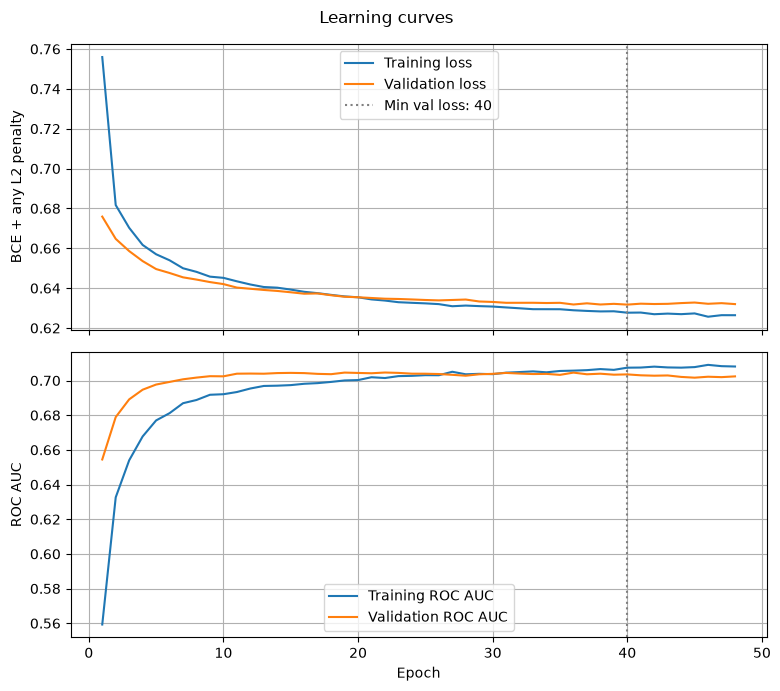

1596/1596 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Training AUC Score      : 0.7164414022251997
Validation AUC Score    : 0.7036231029562633
Validation Accuracy     : 0.6526711577628075
Validation F1           : 0.6816941852117732


In [37]:
# Early Stopping and Dropout to Mitigiate Overfitting

tf.keras.utils.set_random_seed(42)

# New Model
es_model = Sequential([
    Input(shape=(num_features,)),
    Dense(64, activation='relu', kernel_initializer='he_normal',
          kernel_regularizer=regularizers.l2(1e-4)),
    Dropout(0.3),
    Dense(32, activation='relu', kernel_initializer='he_normal',
          kernel_regularizer=regularizers.l2(1e-4)),
    Dropout(0.3),
    Dense(1, activation='sigmoid'),
])

es_opt = Adam(learning_rate=0.001)

es_model.compile(loss='binary_crossentropy',
                 optimizer=es_opt,
                 metrics=[tf.keras.metrics.F1Score(average='macro',threshold=0.5),tf.keras.metrics.AUC(name='auc')]
)

# Add in Early Stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

es_history = es_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=200,
    batch_size=256,
    callbacks=[early_stop],
    verbose=0
)

# Evaluate
plot_history(es_history)

es_train_preds = es_model.predict(X_train_scaled).ravel()
es_val_preds = es_model.predict(X_val_scaled).ravel()

# AUC ROC Scores
es_train_roc = roc_auc_score(y_train, es_train_preds)
es_val_roc = roc_auc_score(y_val, es_val_preds)

# Accuracy & F1 Score
es_val_accuracy = accuracy_score(y_val, es_val_preds >= 0.5)
es_val_f1 = f1_score(y_val, es_val_preds >= 0.5)


print(f"Training AUC Score      : {es_train_roc}")
print(f"Validation AUC Score    : {es_val_roc}")
print(f"Validation Accuracy     : {es_val_accuracy}")
print(f"Validation F1           : {es_val_f1}")

experiment_results.append({
    "Model"            : "Baseline w/ Early Stopping",
    "Training AUC"     : es_train_roc,
    "Validation AUC"   : es_val_roc,
    "Validation Log Loss" : log_loss(y_val, es_val_preds),
    "Validation F1"    : es_val_f1,
    "config"           : es_model.get_config() 
})

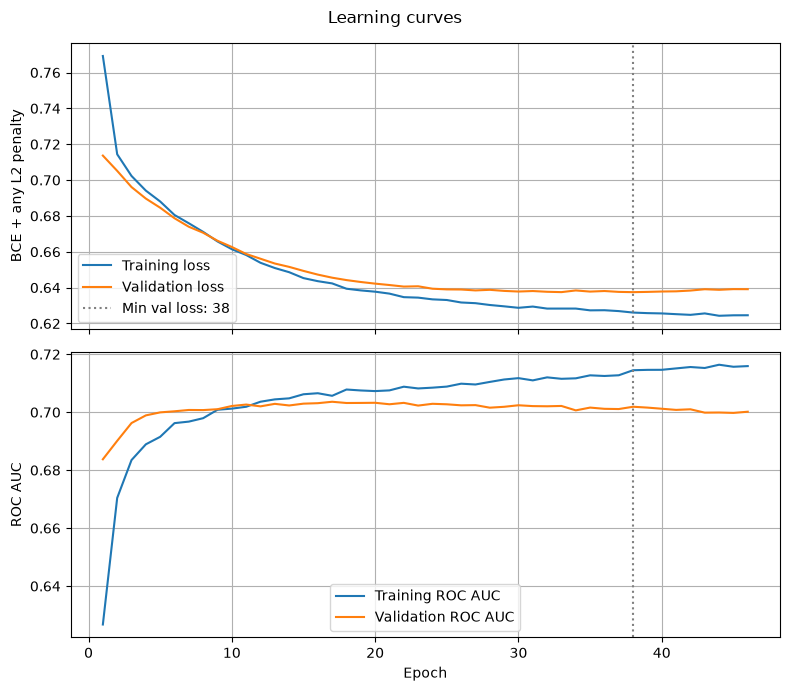

1596/1596 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Training AUC Score      : 0.725266579582043
Validation AUC Score    : 0.7018808296876289
Validation Accuracy     : 0.6468745104182986
Validation F1           : 0.6780919737217938


In [38]:
# Continue with Early Stopping, Investigate More Hidden Layers

tf.keras.utils.set_random_seed(42)

exp3_model = Sequential([
    Input(shape=(num_features,)),
    Dense(256, activation='relu', kernel_initializer='he_normal',
        kernel_regularizer=regularizers.l2(1e-4)),
    Dropout(0.3),
    Dense(128, activation='relu', kernel_initializer='he_normal',
        kernel_regularizer=regularizers.l2(1e-4)),
    Dropout(0.3),
    Dense(1, activation='sigmoid'),
])

exp3_opt = Adam(learning_rate=0.001)

exp3_model.compile(
    loss='binary_crossentropy',
    optimizer=exp3_opt,
    metrics=[tf.keras.metrics.F1Score(average='macro',threshold=0.5),tf.keras.metrics.AUC(name='auc')]
)

exp3_history = exp3_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled,y_val),
    callbacks=[early_stop],
    epochs=200,
    batch_size=256,
    verbose=0
)

# Evaluate
plot_history(exp3_history)

exp3_train_preds = exp3_model.predict(X_train_scaled).ravel()
exp3_val_preds = exp3_model.predict(X_val_scaled).ravel()

# AUC ROC Scores
exp3_train_roc = roc_auc_score(y_train, exp3_train_preds)
exp3_val_roc = roc_auc_score(y_val, exp3_val_preds)

# Accuracy & F1 Score
exp3_val_accuracy = accuracy_score(y_val, exp3_val_preds >= 0.5)
exp3_val_f1 = f1_score(y_val, exp3_val_preds >= 0.5)


print(f"Training AUC Score      : {exp3_train_roc}")
print(f"Validation AUC Score    : {exp3_val_roc}")
print(f"Validation Accuracy     : {exp3_val_accuracy}")
print(f"Validation F1           : {exp3_val_f1}")

experiment_results.append({
    "Model"            : "Early Stopping and More Hidden UnitsAu",
    "Training AUC"     : exp3_train_roc,
    "Validation AUC"   : exp3_val_roc,
    "Validation Log Loss" : log_loss(y_val, exp3_val_preds),
    "Validation F1"    : exp3_val_f1,
    "config"           : exp3_model.get_config() 
})


In [39]:
exp_results = pd.DataFrame(experiment_results)
exp_results

,Model,Training AUC,Validation AUC,Validation Log Loss,Validation F1,config
0,Baseline,0.773900,0.662047,0.685111,0.648145,"{'name': 'sequential_6', 'trainable': True, 'd..."
1,Baseline w/ Early Stopping,0.716441,0.703623,0.627259,0.681694,"{'name': 'sequential_7', 'trainable': True, 'd..."
2,Early Stopping and More Hidden UnitsAu,0.725267,0.701881,0.628737,0.678092,"{'name': 'sequential_8', 'trainable': True, 'd..."


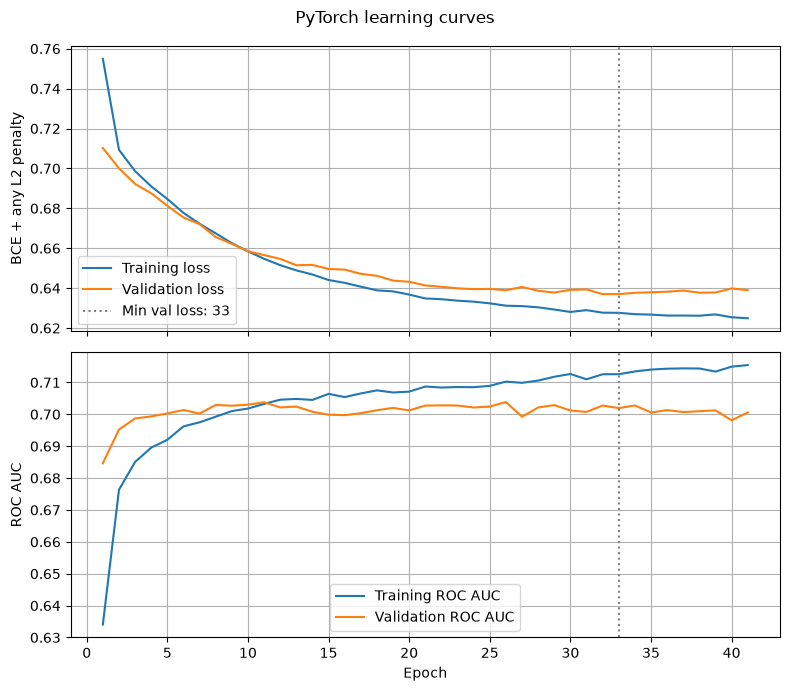

Training AUC Score      : 0.7208756787613508
Validation AUC Score    : 0.7019431309426947
Validation Accuracy     : 0.6539244869183769
Validation F1           : 0.6763369963369963


In [40]:
# The following model was made with AI, as a learning experience with PyTorch
# PyTorch version of exp3_model (Early Stopping and More Hidden Units)
import copy
import math
from types import SimpleNamespace
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)                                   # = tf.keras.utils.set_random_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"

# 1. Data -> tensors -> batches (batch_size=256, reshuffled every epoch like Keras fit)
X_tr = torch.tensor(X_train_scaled, device=device)
X_va = torch.tensor(X_val_scaled, device=device)
y_tr = torch.tensor(y_train.to_numpy(), dtype=torch.float32, device=device).view(-1, 1)
y_va = torch.tensor(y_val.to_numpy(), dtype=torch.float32, device=device).view(-1, 1)
train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=256, shuffle=True)

# 2. Model: 256 -> 128 with Dropout(0.3). No sigmoid at the end: BCEWithLogitsLoss applies it
torch_model = nn.Sequential(
    nn.Linear(num_features, 256), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(128, 1),
).to(device)

# Keras he_normal = truncated normal (cut at 2 std, rescaled), biases start at 0
for layer in torch_model:
    if isinstance(layer, nn.Linear):
        std = math.sqrt(2 / layer.in_features) / 0.87962566103423978
        nn.init.trunc_normal_(layer.weight, std=std, a=-2 * std, b=2 * std)
        nn.init.zeros_(layer.bias)

# Only the two hidden layers have kernel_regularizer=l2(1e-4) in exp3_model
l2_layers = [torch_model[0], torch_model[3]]


def l2_penalty():
    # Keras l2(1e-4) adds 1e-4 * sum(weights^2) to the loss (kernels only, not biases)
    return sum(1e-4 * (layer.weight ** 2).sum() for layer in l2_layers)


# 3. Loss + optimizer (Keras Adam uses epsilon=1e-7, PyTorch defaults to 1e-8)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(torch_model.parameters(), lr=0.001, eps=1e-7)


def predict_proba(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(X)).cpu().numpy().ravel()


# 4 + 5. Training loop with early stopping (monitor val_loss, patience 8, restore best weights)
hist = {"loss": [], "val_loss": [], "auc": [], "val_auc": []}
best_loss, best_weights, patience, bad_epochs = float("inf"), None, 8, 0

for epoch in range(200):
    torch_model.train()
    total = 0
    batch_preds, batch_targets = [], []
    for xb, yb in train_loader:
        optimizer.zero_grad()
        logits = torch_model(xb)
        loss = loss_fn(logits, yb) + l2_penalty()       # Keras training loss includes the L2 penalty
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
        batch_preds.append(torch.sigmoid(logits).detach().cpu())
        batch_targets.append(yb.cpu())
    hist["loss"].append(total / len(X_tr))
    # Keras training AUC is measured on the batches as they train (dropout on), not a separate pass
    hist["auc"].append(roc_auc_score(torch.cat(batch_targets).numpy(), torch.cat(batch_preds).numpy()))

    torch_model.eval()
    with torch.no_grad():
        val_loss = (loss_fn(torch_model(X_va), y_va) + l2_penalty()).item()   # Keras val_loss includes it too
    hist["val_loss"].append(val_loss)
    hist["val_auc"].append(roc_auc_score(y_val, predict_proba(torch_model, X_va)))

    if val_loss < best_loss:
        best_loss, best_weights, bad_epochs = val_loss, copy.deepcopy(torch_model.state_dict()), 0
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            break

torch_model.load_state_dict(best_weights)

# 6. Evaluate (plot_history expects an object with a .history dict, like Keras)
plot_history(SimpleNamespace(history=hist), title="PyTorch learning curves")

torch_train_preds = predict_proba(torch_model, X_tr)
torch_val_preds = predict_proba(torch_model, X_va)

# AUC ROC Scores
torch_train_roc = roc_auc_score(y_train, torch_train_preds)
torch_val_roc = roc_auc_score(y_val, torch_val_preds)

# Accuracy & F1 Score
torch_val_accuracy = accuracy_score(y_val, torch_val_preds >= 0.5)
torch_val_f1 = f1_score(y_val, torch_val_preds >= 0.5)

print(f"Training AUC Score      : {torch_train_roc}")
print(f"Validation AUC Score    : {torch_val_roc}")
print(f"Validation Accuracy     : {torch_val_accuracy}")
print(f"Validation F1           : {torch_val_f1}")

experiment_results.append({
    "Model"            : "PyTorch: Early Stopping and More Hidden Units",
    "Training AUC"     : torch_train_roc,
    "Validation AUC"   : torch_val_roc,
    "Validation Log Loss" : log_loss(y_val, torch_val_preds),
    "Validation F1"    : torch_val_f1,
    "config"           : str(torch_model),
})


In [41]:
# Naive Model Comparison
naive_prob = np.full(len(y_val), y_train.mean())
naive_train_prob = np.full(len(y_train), y_train.mean())

experiment_results.append({
    "Model"             : "Naive (training rate)",
    "Training AUC"      : roc_auc_score(y_train, naive_train_prob),
    "Validation AUC"    : roc_auc_score(y_val, naive_prob),
    "Validation Log Loss" : log_loss(y_val, naive_prob),
    "Validation F1"     : f1_score(y_val, naive_prob >= 0.5),
    "config"            : None
})

exp_results = pd.DataFrame(experiment_results)
exp_results

,Model,Training AUC,Validation AUC,Validation Log Loss,Validation F1,config
0,Baseline,0.773900,0.662047,0.685111,0.648145,"{'name': 'sequential_6', 'trainable': True, 'd..."
1,Baseline w/ Early Stopping,0.716441,0.703623,0.627259,0.681694,"{'name': 'sequential_7', 'trainable': True, 'd..."
2,Early Stopping and More Hidden UnitsAu,0.725267,0.701881,0.628737,0.678092,"{'name': 'sequential_8', 'trainable': True, 'd..."
3,PyTorch: Early Stopping and More Hidden Units,0.720876,0.701943,0.627975,0.676337,"Sequential(\n (0): Linear(in_features=40, out..."
4,Naive (training rate),0.500000,0.500000,0.692690,0.679971,None


In [ ]:
# Final Model
print(f"Best Model: {exp_results.set_index('Model')['Validation Log Loss'].idxmin()}")

Best Model: Baseline w/ Early Stopping


In [46]:
# Score the chosen model once on the test set
test_preds = es_model.predict(X_test_scaled, verbose=0).ravel()

test_auc = roc_auc_score(y_test, test_preds)
test_f1 = f1_score(y_test, test_preds >= 0.5)
test_acc = accuracy_score(y_test, test_preds >= 0.5)
test_log_loss = log_loss(y_test, test_preds)

# Naive model on the test set for reference (always predict the training conversion rate)
naive_test_prob = np.full(len(y_test), y_train.mean())
naive_test_log_loss = log_loss(y_test, naive_test_prob)
naive_test_acc = accuracy_score(y_test, naive_test_prob >= 0.5)

print("Test Results: Baseline w/ Early Stopping")
print(f"Test AUC Score          : {test_auc:.4f}")
print(f"Test Log Loss           : {test_log_loss:.4f}   (naive: {naive_test_log_loss:.4f})")
print(f"Test Accuracy           : {test_acc:.4f}   (naive: {naive_test_acc:.4f})")
print(f"Test F1                 : {test_f1:.4f}")


Test Results: Baseline w/ Early Stopping
Test AUC Score          : 0.7007
Test Log Loss           : 0.6287   (naive: 0.6928)
Test Accuracy           : 0.6452   (naive: 0.5136)
Test F1                 : 0.6723


# Conclusion

**1. Purpose** 

The goal of this notebook was to find a model that could predict the probability that a team would convert on a fourth down.


**2. Data**

Source: `marts.fourth_down_features` - all fourth down attempts in the dataset where the decision was made to 'go for it'
Splits: Trained on 2014-2023 yearly seasons, validated on 2024 season, tested once on 2025 season.
Notes: Prediction target was created based off the yards gained on the play being greater than or less than the distance to the first down.


**3. Results (2025 Test Season)**

- The accuracy of the test dataset was almost 25% better than the naive model
- A testing log loss of 0.6287 means that the model is performing better than a random guess and the probabilities that are being prediction are somewhat reasonable
- A testing AUC score of .7 means the model has a somewhat moderate change to accurately discriminate between positive and negative instances

**4. What Worked vs What Didnt**

PLACE HERE

**5. Limitations**

PLACE HERE

**6. Possible Improvements**

- This model could benefit from more descriptive features
- maybe add more team based statistics